In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adenly жобасының оқу жоспары
TOTAL_WEEKS = 14
CURRENT_WEEK = 6
REMAINING_WEEKS = TOTAL_WEEKS - CURRENT_WEEK

# 1–6 апталар үшін мысалдық деректер
# Нақты GitHub статистикасы емес
history = [2, 3, 4, 3, 5, 4]

df = pd.DataFrame({
    "Апта": range(1, CURRENT_WEEK + 1),
    "Орындалған тапсырмалар": history
})

print("ADENLY — ЛЗ №6")
print("Жалпы оқу аптасы:", TOTAL_WEEKS)
print("Қазіргі апта:", CURRENT_WEEK)
print("Қалған апта:", REMAINING_WEEKS)

display(df)

print("\nСТАТИСТИКА")
print("Орташа:", round(np.mean(history), 2))
print("Медиана:", np.median(history))
print("Минимум:", np.min(history))
print("Максимум:", np.max(history))
print("Барлығы орындалған:", sum(history))


ADENLY — ЛЗ №6
Жалпы оқу аптасы: 14
Қазіргі апта: 6
Қалған апта: 8


,Апта,Орындалған тапсырмалар
0,1,2
1,2,3
2,3,4
3,4,3
4,5,5
5,6,4



СТАТИСТИКА
Орташа: 3.5
Медиана: 3.5
Минимум: 2
Максимум: 5
Барлығы орындалған: 21


In [ ]:

# Adenly жобасының тапсырмалары
TOTAL_TASKS = 50       # Оқу мысалы
COMPLETED_TASKS = 21   # Алдыңғы мысалдық деректердің қосындысы

BACKLOG = TOTAL_TASKS - COMPLETED_TASKS

print("ADENLY — ТАПСЫРМАЛАР")
print("Жалпы тапсырмалар:", TOTAL_TASKS)
print("Орындалған:", COMPLETED_TASKS)
print("Қалған:", BACKLOG)
print("Қалған уақыт:", REMAINING_WEEKS, "апта")


ADENLY — ТАПСЫРМАЛАР
Жалпы тапсырмалар: 50
Орындалған: 21
Қалған: 29
Қалған уақыт: 8 апта


In [ ]:

# Монте-Карло симуляциясы
rng = np.random.default_rng(42)

RUNS = 10000
weeks = np.empty(RUNS, dtype=int)

for i in range(RUNS):
    done = 0
    w = 0

    while done < BACKLOG:
        weekly_tasks = rng.choice(history)
        done += weekly_tasks
        w += 1

    weeks[i] = w

print("ADENLY — МОНТЕ-КАРЛО")
print("Симуляция саны:", RUNS)

for p in [50, 70, 85, 95]:
    result = int(np.ceil(np.percentile(weeks, p)))
    print(f"P{p}: {result} апта")

probability = np.mean(weeks <= REMAINING_WEEKS) * 100

print(
    f"\n8 апта ішінде аяқталу ықтималдығы: "
    f"{probability:.2f}%"
)


ADENLY — МОНТЕ-КАРЛО
Симуляция саны: 10000
P50: 9 апта
P70: 9 апта
P85: 9 апта
P95: 10 апта

8 апта ішінде аяқталу ықтималдығы: 42.57%


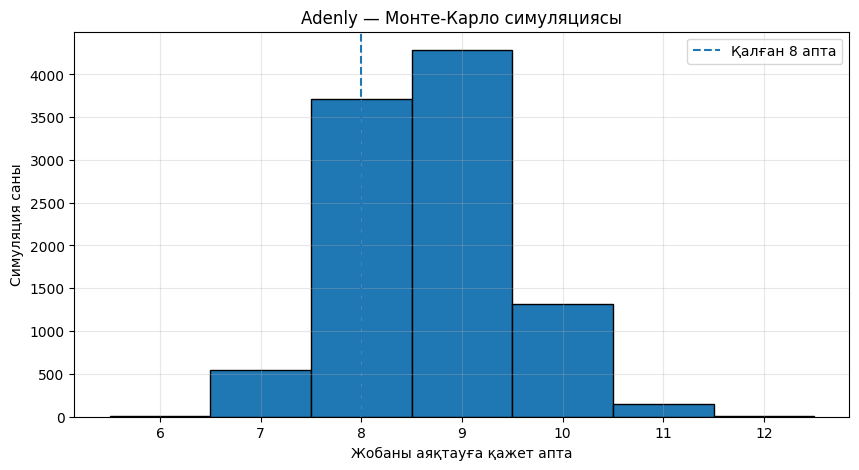

In [ ]:

plt.figure(figsize=(10, 5))

plt.hist(
    weeks,
    bins=np.arange(weeks.min(), weeks.max() + 2) - 0.5,
    edgecolor="black"
)

plt.axvline(
    REMAINING_WEEKS,
    linestyle="--",
    label="Қалған 8 апта"
)

plt.title("Adenly — Монте-Карло симуляциясы")
plt.xlabel("Жобаны аяқтауға қажет апта")
plt.ylabel("Симуляция саны")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


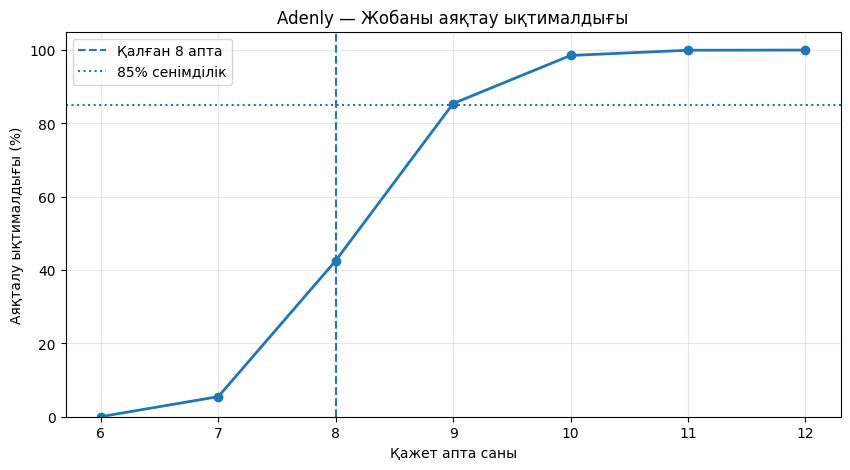

,Апта,Аяқталу ықтималдығы (%)
0,6,0.02
1,7,5.48
2,8,42.57
3,9,85.42
4,10,98.53
5,11,99.95
6,12,100.00


In [ ]:

# Жинақталған ықтималдық графигі

unique_weeks = np.arange(weeks.min(), weeks.max() + 1)

probabilities = [
    np.mean(weeks <= w) * 100
    for w in unique_weeks
]

plt.figure(figsize=(10, 5))

plt.plot(
    unique_weeks,
    probabilities,
    marker="o",
    linewidth=2
)

plt.axvline(
    8,
    linestyle="--",
    label="Қалған 8 апта"
)

plt.axhline(
    85,
    linestyle=":",
    label="85% сенімділік"
)

plt.title("Adenly — Жобаны аяқтау ықтималдығы")
plt.xlabel("Қажет апта саны")
plt.ylabel("Аяқталу ықтималдығы (%)")

plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

# Нәтижелерді кестеге шығару
result_df = pd.DataFrame({
    "Апта": unique_weeks,
    "Аяқталу ықтималдығы (%)":
        np.round(probabilities, 2)
})

display(result_df)


In [ ]:

import pandas as pd
import numpy as np

PROJECT_START = pd.Timestamp("2026-09-11")
CURRENT_WEEK = 6
TOTAL_WEEKS = 14

# 6-аптаның басталуы
FORECAST_DATE = PROJECT_START + pd.Timedelta(
    weeks=CURRENT_WEEK - 1
)

# 14 апталық оқу жоспарының соңғы күні
DEADLINE = PROJECT_START + pd.Timedelta(
    weeks=TOTAL_WEEKS
) - pd.Timedelta(days=1)

results = []

for p in [50, 70, 85, 95]:
    w = int(np.ceil(np.percentile(weeks, p)))
    finish = FORECAST_DATE + pd.Timedelta(weeks=w)

    results.append({
        "Көрсеткіш": f"P{p}",
        "Қажет апта": w,
        "Болжамды күн": finish.strftime("%d.%m.%Y")
    })

print("Жоба басталған күн:", PROJECT_START.strftime("%d.%m.%Y"))
print("Бағалау күні:", FORECAST_DATE.strftime("%d.%m.%Y"))
print("14-аптаның соңғы күні:", DEADLINE.strftime("%d.%m.%Y"))

display(pd.DataFrame(results))


Жоба басталған күн: 11.09.2026
Бағалау күні: 16.10.2026
14-аптаның соңғы күні: 17.12.2026


,Көрсеткіш,Қажет апта,Болжамды күн
0,P50,9,18.12.2026
1,P70,9,18.12.2026
2,P85,9,18.12.2026
3,P95,10,25.12.2026


In [ ]:

import pandas as pd

stories = [
    "US-01 Тіркеу",
    "US-02 Жүйеге кіру",
    "US-03 Рөлдерді басқару",
    "US-04 Профильді өзгерту",
    "US-05 Курстар тізімі",
    "US-06 Курсқа тіркелу",
    "US-07 Материалдарды жүктеу",
    "US-08 Тапсырмаларды жіберу",
    "US-09 Бағалау жүйесі",
    "US-10 Хабарландыру"
]

# Бірінші раундтың мысалдық бағалары
poker = pd.DataFrame({
    "User Story": stories,
    "Арнұр": [3, 3, 5, 3, 5, 5, 8, 8, 8, 5],
    "Шыңғыс": [3, 2, 5, 2, 3, 5, 8, 5, 8, 3],
    "Абдулазиз": [5, 3, 8, 3, 5, 8, 13, 8, 13, 5],
    "Қайсар": [3, 3, 5, 3, 5, 5, 8, 8, 8, 5]
})

members = ["Арнұр", "Шыңғыс", "Абдулазиз", "Қайсар"]

poker["Минимум"] = poker[members].min(axis=1)
poker["Максимум"] = poker[members].max(axis=1)
poker["Айырмашылық"] = poker["Максимум"] - poker["Минимум"]

display(poker)


,User Story,Арнұр,Шыңғыс,Абдулазиз,Қайсар,Минимум,Максимум,Айырмашылық
0,US-01 Тіркеу,3,3,5,3,3,5,2
1,US-02 Жүйеге кіру,3,2,3,3,2,3,1
2,US-03 Рөлдерді басқару,5,5,8,5,5,8,3
3,US-04 Профильді өзгерту,3,2,3,3,2,3,1
4,US-05 Курстар тізімі,5,3,5,5,3,5,2
5,US-06 Курсқа тіркелу,5,5,8,5,5,8,3
6,US-07 Материалдарды жүктеу,8,8,13,8,8,13,5
7,US-08 Тапсырмаларды жіберу,8,5,8,8,5,8,3
8,US-09 Бағалау жүйесі,8,8,13,8,8,13,5
9,US-10 Хабарландыру,5,3,5,5,3,5,2


In [ ]:

# Planning Poker — екінші раунд
# Бұл келісілген бағалардың мысалы.
# Нақты команда шешімімен ауыстыру қажет.

final_sp = [3, 3, 5, 3, 5, 5, 8, 8, 8, 5]

poker["Келісілген SP"] = final_sp

print("ADENLY — PLANNING POKER НӘТИЖЕСІ")
display(poker)

total_sp = sum(final_sp)

print("\nБарлық Story Points:", total_sp)
print("User Story саны:", len(stories))
print("Орташа күрделілік:", round(total_sp / len(stories), 2))


ADENLY — PLANNING POKER НӘТИЖЕСІ


,User Story,Арнұр,Шыңғыс,Абдулазиз,Қайсар,Минимум,Максимум,Айырмашылық,Келісілген SP
0,US-01 Тіркеу,3,3,5,3,3,5,2,3
1,US-02 Жүйеге кіру,3,2,3,3,2,3,1,3
2,US-03 Рөлдерді басқару,5,5,8,5,5,8,3,5
3,US-04 Профильді өзгерту,3,2,3,3,2,3,1,3
4,US-05 Курстар тізімі,5,3,5,5,3,5,2,5
5,US-06 Курсқа тіркелу,5,5,8,5,5,8,3,5
6,US-07 Материалдарды жүктеу,8,8,13,8,8,13,5,8
7,US-08 Тапсырмаларды жіберу,8,5,8,8,5,8,3,8
8,US-09 Бағалау жүйесі,8,8,13,8,8,13,5,8
9,US-10 Хабарландыру,5,3,5,5,3,5,2,5



Барлық Story Points: 53
User Story саны: 10
Орташа күрделілік: 5.3


In [11]:

import pandas as pd
import numpy as np

# Монте-Карло нәтижелері
p85 = int(np.ceil(np.percentile(weeks, 85)))
p95 = int(np.ceil(np.percentile(weeks, 95)))

probability = np.mean(
    weeks <= REMAINING_WEEKS
) * 100

summary = pd.DataFrame({
    "Көрсеткіш": [
        "Жалпы оқу мерзімі",
        "Қазіргі апта",
        "Қалған апта",
        "Қалған тапсырмалар",
        "Planning Poker бағасы",
        "P85 мерзімі",
        "P95 мерзімі",
        "8 аптада аяқталу ықтималдығы"
    ],
    "Нәтиже": [
        "14 апта",
        "6-апта",
        "8 апта",
        f"{BACKLOG} тапсырма",
        f"{total_sp} SP (10 User Story)",
        f"{p85} апта",
        f"{p95} апта",
        f"{probability:.2f}%"
    ]
})

print("ADENLY — ЛЗ №6 ҚОРЫТЫНДЫСЫ")
display(summary)

print("\nҰСЫНЫС:")
print("1. Маңызды функцияларды бірінші аяқтау.")
print("2. Үлкен тапсырмаларды кіші бөліктерге бөлу.")
print("3. Апта сайын жұмыс жылдамдығын бақылау.")
print("4. Нақты деректер жиналған сайын болжамды жаңарту.")


ADENLY — ЛЗ №6 ҚОРЫТЫНДЫСЫ


,Көрсеткіш,Нәтиже
0,Жалпы оқу мерзімі,14 апта
1,Қазіргі апта,6-апта
2,Қалған апта,8 апта
3,Қалған тапсырмалар,29 тапсырма
4,Planning Poker бағасы,53 SP (10 User Story)
5,P85 мерзімі,9 апта
6,P95 мерзімі,10 апта
7,8 аптада аяқталу ықтималдығы,42.57%



ҰСЫНЫС:
1. Маңызды функцияларды бірінші аяқтау.
2. Үлкен тапсырмаларды кіші бөліктерге бөлу.
3. Апта сайын жұмыс жылдамдығын бақылау.
4. Нақты деректер жиналған сайын болжамды жаңарту.
